# 02 — Baseline: Pretrained CLIP + FAISS

The baseline uses **no training at all**:
1. Encode every logo with a pretrained CLIP image encoder (ViT-B/32) -> 512-d vector.
2. Normalise the vectors and search with FAISS by cosine similarity.

### Evaluation protocol (test split only)
* Every test image is used once as a **query**; the gallery is every other test image.
* A result is **correct** when it has the same `parent_id` as the query.
* **Recall@K**: share of queries with at least one correct result in the top K.
* **mAP**: mean average precision, i.e. how high *all* correct results are ranked.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

DATA_DIR = ROOT / "data" / "dummy_logos"
IMAGE_DIR = DATA_DIR / "images"
ASSETS = ROOT / "assets"
RESULTS = ROOT / "results"
MODELS = ROOT / "models"
for d in (ASSETS, RESULTS, MODELS):
    d.mkdir(exist_ok=True)
SEED = 42

import json
import numpy as np
import pandas as pd
import faiss
from model import get_device, load_clip, embed_paths
from metrics import retrieval_eval, summarize, top_k
from viz import show_retrieval

device = get_device()
print("device:", device)
df = pd.read_csv(DATA_DIR / "metadata.csv")

device: cpu


## 1. Extract CLIP embeddings
Takes ~5-15 min on a laptop CPU for 9,000 images; cached to `data/embeddings_clip.npy` afterwards.

In [2]:
EMB_PATH = ROOT / "data" / "embeddings_clip.npy"

if EMB_PATH.exists():
    emb = np.load(EMB_PATH)
    print("Loaded cached embeddings")
else:
    clip_model, preprocess = load_clip(device)
    paths = [IMAGE_DIR / f for f in df.filename]
    emb = embed_paths(paths, clip_model, preprocess, device=device, batch_size=64)
    np.save(EMB_PATH, emb)

assert len(emb) == len(df)
print(emb.shape)

  batch 20/141
  batch 40/141
  batch 60/141
  batch 80/141
  batch 100/141
  batch 120/141
  batch 140/141
  batch 141/141
(9000, 512)


## 2. Build a FAISS index
`IndexFlatIP` = exact inner-product search. Because the vectors are L2-normalised, inner product = cosine similarity.

In [3]:
test_mask = (df.split == "test").values
test_df = df[test_mask].reset_index(drop=True)
test_emb = emb[test_mask].astype(np.float32)

index = faiss.IndexFlatIP(test_emb.shape[1])
index.add(test_emb)
print("vectors in index:", index.ntotal)

# Example search: top 5 for the first test image (position 0 is the image itself)
scores, ids = index.search(test_emb[:1], 6)
test_df.loc[ids[0], ["filename", "parent_id", "brand_text"]].assign(score=scores[0])

vectors in index: 1350


,filename,parent_id,brand_text,score
0,p0007_v00.png,7,Peda Food,1.000000
5,p0007_v05.png,7,Peda Food,0.966042
7,p0007_v07.png,7,Peda Food,0.955428
1,p0007_v01.png,7,Peda Food,0.914693
8,p0007_v08.png,7,Peda Food,0.903693
6,p0007_v06.png,7,Peda,0.742677


## 3. Evaluate the baseline

In [4]:
per_query = retrieval_eval(test_emb, test_df.parent_id.values)
baseline = summarize(per_query)

with open(RESULTS / "baseline_metrics.json", "w") as f:
    json.dump(baseline, f, indent=2)

pd.Series(baseline, name="CLIP baseline").to_frame().style.format("{:.3f}")

,CLIP baseline
recall@1,0.917
recall@5,0.949
recall@10,0.957
mAP,0.690


## 4. What the baseline retrieves
Green frame = same mark as the query, red = different mark.

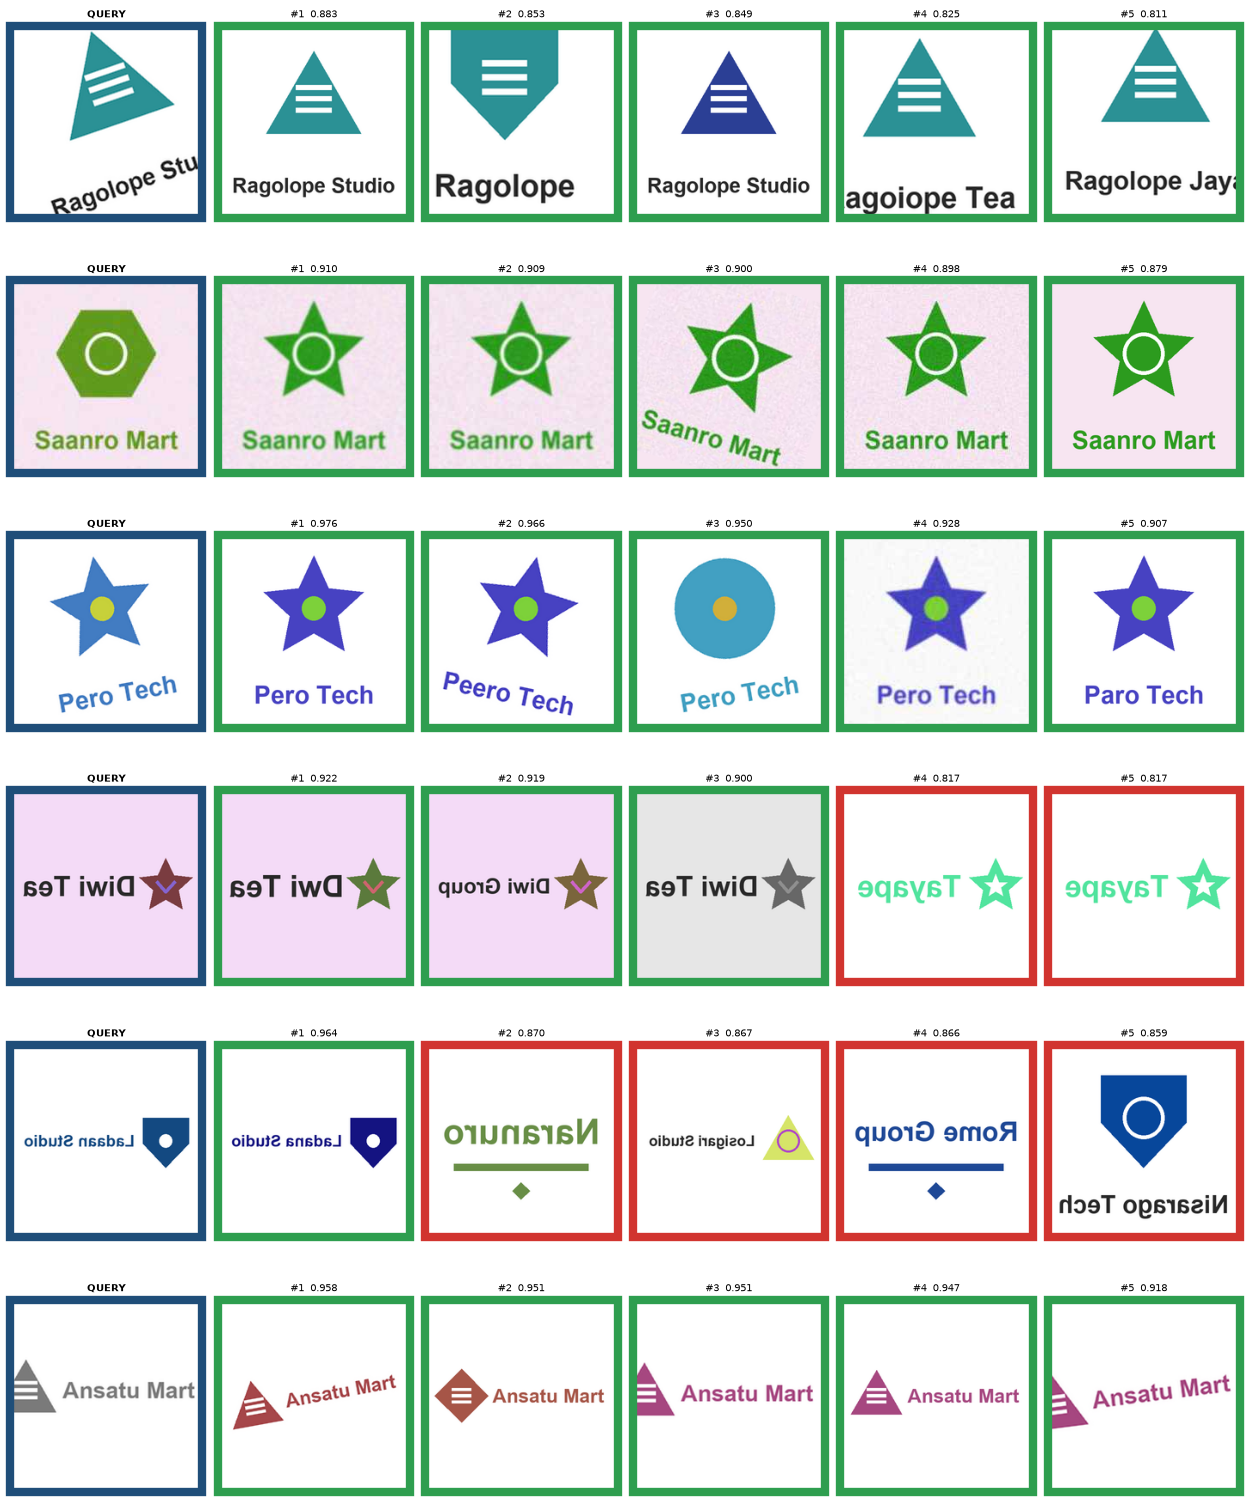

In [5]:
rng = np.random.default_rng(SEED)
q_idx = rng.choice(len(test_df), 6, replace=False)
nn_idx, nn_scores = top_k(test_emb, q_idx, k=5)

paths = test_df.filename.map(lambda f: IMAGE_DIR / f).values
labels = test_df.parent_id.values
show_retrieval(
    query_paths=paths[q_idx],
    result_paths=[paths[r] for r in nn_idx],
    result_scores=nn_scores,
    result_correct=[labels[r] == labels[q] for q, r in zip(q_idx, nn_idx)],
    save_path=ASSETS / "baseline_examples.png")

## Observations
* Pretrained CLIP already finds at least one variant of the same mark at rank 1 for
  **91.7%** of queries (Recall@5 = 94.9%), without any training.
* It is robust to many modifications: rotation, colour changes, grayscale, typos and
  similar replacement shapes are mostly retrieved correctly.
* However, **mAP is only 0.690**: not all variants of a mark are ranked at the top.
* The clearest failure pattern is **mirrored (flipped) logos**: a flipped query tends to
  retrieve *other marks that are also flipped* (reversed text looks alike to CLIP),
  instead of the original version of the same mark.
* For trademark clearance this matters: a consultant needs *all* potentially conflicting
  marks near the top of the list, not just one.

CLIP was trained on natural photos and captions, not on "is this the same trademark".
Next notebook: teach it that notion with a small projection head trained with triplet loss.